Day 4: CNN Basics

Today I am learning how convolutional neural networks work with images. I will explore filters, feature maps, stride, padding, and pooling, then train a small CNN on FashionMNIST.

Goals
- Understand why CNNs are useful for images
- Inspect convolution outputs and feature maps
- See how stride, padding, and pooling change image dimensions
- Build and train a basic CNN

Why CNN?

Images have spatial structure: nearby pixels can form edges, corners, and textures. A fully connected network flattens the image immediately, while a CNN processes the image as a grid and learns filters that detect local patterns.

A common CNN contains convolution layers, activation functions such as ReLU, pooling layers, and a final classifier.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


Load FashionMNIST

FashionMNIST contains 28 × 28 grayscale clothing images. A batch has shape `[batch_size, channels, height, width]`; grayscale images have one channel.

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 342kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.3MB/s]


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


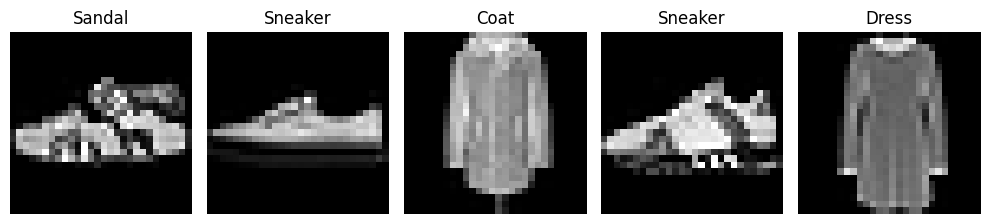

In [2]:
transform = transforms.ToTensor()
train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)

BATCH_SIZE = 64
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()

Convolution and feature maps

A convolutional layer learns filters (kernels) that move across an image and calculate values from small regions. Its output is called a **feature map**.

`nn.Conv2d(1, 8, kernel_size=3)` takes a one-channel image and learns 8 filters of size 3 × 3.

In [3]:
one_image = images[:1]  # [batch, channels, height, width]
conv = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3)
feature_maps = conv(one_image)

print("Input shape:", one_image.shape)
print("Feature map shape:", feature_maps.shape)

Input shape: torch.Size([1, 1, 28, 28])
Feature map shape: torch.Size([1, 8, 26, 26])


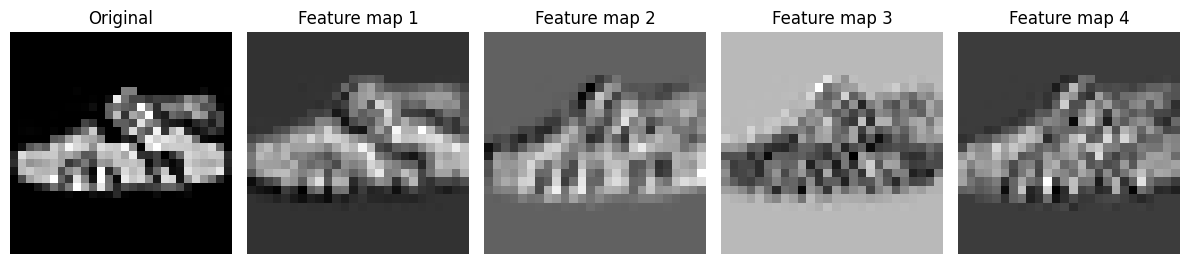

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
axes[0].imshow(one_image[0, 0], cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")
for i in range(4):
    axes[i + 1].imshow(feature_maps[0, i].detach(), cmap="gray")
    axes[i + 1].set_title(f"Feature map {i + 1}")
    axes[i + 1].axis("off")
plt.tight_layout()
plt.show()

Stride and padding

**Stride** is how far a filter moves each time. A larger stride generally makes the output smaller.

**Padding** adds pixels around the image border and can help preserve dimensions.

For one spatial dimension:

`output = floor((input + 2 × padding − kernel_size) / stride) + 1`

For an input size of 28 and a 3 × 3 kernel with stride 1: no padding gives size 26; padding 1 gives size 28.

In [5]:
sample = torch.randn(1, 1, 28, 28)
conv_default = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=0)
conv_padded = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)
conv_stride2 = nn.Conv2d(1, 4, kernel_size=3, stride=2, padding=0)

print("No padding:", conv_default(sample).shape)
print("Padding 1:", conv_padded(sample).shape)
print("Stride 2:", conv_stride2(sample).shape)

No padding: torch.Size([1, 4, 26, 26])
Padding 1: torch.Size([1, 4, 28, 28])
Stride 2: torch.Size([1, 4, 13, 13])


Pooling

Pooling reduces feature-map width and height. `MaxPool2d(2)` takes the maximum from each 2 × 2 region and typically halves both dimensions.

In [6]:
pool = nn.MaxPool2d(kernel_size=2)
pooled_maps = pool(feature_maps)
print("Before pooling:", feature_maps.shape)
print("After pooling:", pooled_maps.shape)

Before pooling: torch.Size([1, 8, 26, 26])
After pooling: torch.Size([1, 8, 13, 13])


Build a small CNN

This model uses two convolution layers, each followed by ReLU and max pooling. The image dimensions go from 28 × 28 to 14 × 14, then to 7 × 7. The final feature tensor has 32 channels, so the flattened size is `32 × 7 × 7`.

In [7]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = FashionCNN().to(device)
print(model)
with torch.no_grad():
    print("Output shape for 4 images:", model(images[:4].to(device)).shape)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=10, bias=True)
  )
)
Output shape for 4 images: torch.Size([4, 10])


Train the CNN

This uses the same training steps as Day 3: forward pass, loss calculation, clear old gradients, backpropagation, and optimizer update.

In [8]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for batch_images, batch_labels in loader:
        batch_images, batch_labels = batch_images.to(device), batch_labels.to(device)
        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        n = batch_labels.size(0)
        total_loss += loss.item() * n
        correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total += n
    return total_loss / total, correct / total

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for batch_images, batch_labels in loader:
            batch_images, batch_labels = batch_images.to(device), batch_labels.to(device)
            logits = model(batch_images)
            loss = loss_fn(logits, batch_labels)
            n = batch_labels.size(0)
            total_loss += loss.item() * n
            correct += (logits.argmax(dim=1) == batch_labels).sum().item()
            total += n
    return total_loss / total, correct / total

In [9]:
EPOCHS = 3
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    test_loss, test_acc = evaluate(model, test_loader)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss {train_loss:.4f} | "
          f"train accuracy {train_acc:.2%} | test loss {test_loss:.4f} | "
          f"test accuracy {test_acc:.2%}")

Epoch 1/3 | train loss 0.5099 | train accuracy 82.12% | test loss 0.4007 | test accuracy 85.75%
Epoch 2/3 | train loss 0.3411 | train accuracy 87.92% | test loss 0.3462 | test accuracy 87.98%
Epoch 3/3 | train loss 0.3031 | train accuracy 89.25% | test loss 0.3139 | test accuracy 88.67%


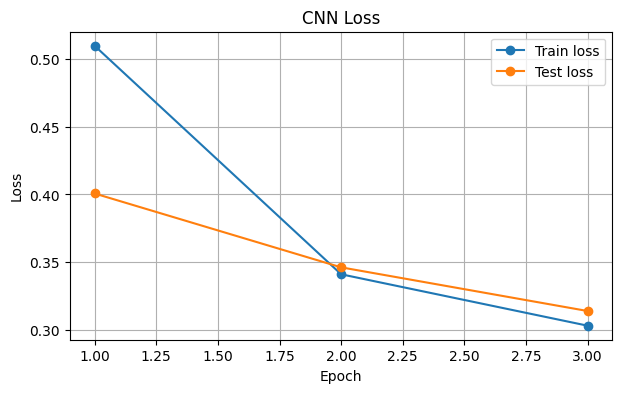

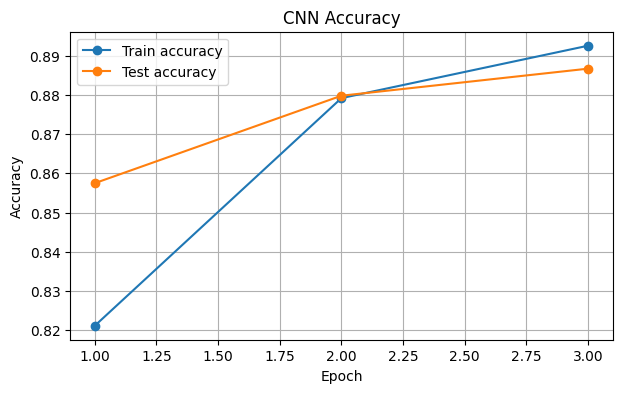

In [10]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs, history["test_loss"], marker="o", label="Test loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("CNN Loss")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_acc"], marker="o", label="Train accuracy")
plt.plot(epochs, history["test_acc"], marker="o", label="Test accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("CNN Accuracy")
plt.legend(); plt.grid(True); plt.show()

Exercises

1. Change the first convolution from 16 output channels to 8. Which other layer must change?
2. Explain convolution, feature maps, stride, padding, and pooling in your own words.
3. Compare this CNN with the MLP from Day 3. Why might a CNN work better for images?
4. Print the final test accuracy.

Answers
1. Change the second convolution's `in_channels` from 16 to 8. The flattened size stays `32 × 7 × 7` if the second stage is unchanged.
2. Convolution applies learned filters to local regions; a feature map is a filter's output; stride is the step size; padding adds border pixels; pooling reduces spatial dimensions.
3. CNNs preserve image layout and reuse filters across locations, helping them learn spatial patterns such as edges and textures.
4. Run: `print(f"Final test accuracy: {history['test_acc'][-1]:.2%}")`

In [11]:
print(f"Final test accuracy: {history['test_acc'][-1]:.2%}")

Final test accuracy: 88.67%


Day 4 summary

Today I inspected convolution outputs, compared stride and padding, used max pooling, and trained a small CNN on FashionMNIST. Before moving on, I should be able to explain how each layer changes the image dimensions and what the training loop is doing.